# Matrius amb numpy

Una matriu és un array, que "té forma" de matriu.

In [ ]:
import numpy as np

a = np.array(range(10), float)
print(a)
a = a.reshape((5, 2))
print(a)

print(a[3][1])

També podem fer servir np.zeros(). Les dimensions es posen entre parèntesis. Hi haurà DOS parèntesis np.zeros((...))

In [ ]:
aa=np.zeros((5,4))
print(aa)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


Una matriu es pot definir a partir dels seus valors. Cada fila és un array, i la matriu és un array d'arrays.

In [ ]:
m=np.array([[1,2,3,4],[5,6,7,8],[9,0,1,2]])
print(m)
print(m[2][1])

Podem treballar amb només una part d'una matriu.

In [ ]:
m=np.array([[1,2,3,4,5,6,7,8],[2,3,4,5,6,7,8,9],[3,4,5,6,7,8,9,0],[4,5,6,7,8,9,0,1],[5,6,7,8,9,0,1,2]])
print(m)
print("*"*20)
print(m[2:4,1:5])

[[1 2 3 4 5 6 7 8]
 [2 3 4 5 6 7 8 9]
 [3 4 5 6 7 8 9 0]
 [4 5 6 7 8 9 0 1]
 [5 6 7 8 9 0 1 2]]
********************
[[4 5 6 7]
 [5 6 7 8]]


Podem multiplicar una matriu m x n per un vector de m coordenades i el resultat és un vector de n coordenades.

In [ ]:
b=np.array([1,2,3,4,5,6,7,8])
x=m.dot(b)
print(x)

[204 240 196 162 138]


També podem invertir una matriu, si és invertible.

In [ ]:
A=np.array([[1,2,3,4],[3,-1,6,0],[1,1,-2,-2],[0,0,-1,-2]])
B= np.linalg.inv(A)
print("A : ")
print(A)
print("B : ")
print(B)

A : 
[[ 1  2  3  4]
 [ 3 -1  6  0]
 [ 1  1 -2 -2]
 [ 0  0 -1 -2]]
B : 
[[-0.29411765  0.17647059  0.76470588 -1.35294118]
 [ 0.52941176 -0.11764706 -0.17647059  1.23529412]
 [ 0.23529412  0.05882353 -0.41176471  0.88235294]
 [-0.11764706 -0.02941176  0.20588235 -0.94117647]]


Per tant, podem resoldre un sistema lineal compatible determinat.

In [ ]:
b=np.array([1,1,1,1])
x=np.linalg.inv(A).dot(b)
print(x)

[-0.70588235  1.47058824  0.76470588 -0.88235294]


També es pot fer amb la funció `solve` de `numpy.linalg`.

In [ ]:
x=np.linalg.solve(A,b)
print(x)

[-0.70588235  1.47058824  0.76470588 -0.88235294]


En les matrius, el primer índex indica la fila, i el segon la columna.

Nosaltres hem utilitzat el primer índex per a la x i el segon per a la y (o la t). Per tant, les matrius estaran transposades, respecte a l'ordre habitual dels eixos. Ho haurem de tenir en compte quan volguem fer una gràfica de la funció.

# Gràfiques de funcions en 3D

Per fer una gràfica en 3D, hem de discretitzar dos intervals i demanar a numpy que els interpreti com una malla en el pla.

Després, a cada punt podem calcular la funció.
El resultat (en el codi, Z) és una matriu que guarda els valors de la funció a cada punt.

Per fer el dibuix, hem de:
*   crear una figura
*   afegir els eixos (en el codi, ax)
*   dibuixar la funció (hi ha diversos modes, nosaltres hem triat el wireframe),
*   mostrar el dibuix (amb la instrucció show()).

Es pot dibuixar més d'una funció en els mateixos eixos.

[[-0.         -0.0788879  -0.15777581 ... -2.36663714 -2.44552505
  -2.52441295]
 [-0.         -0.07379969 -0.14759937 ... -2.21399057 -2.28779026
  -2.36158994]
 [-0.         -0.06806331 -0.13612662 ... -2.04189934 -2.10996265
  -2.17802597]
 ...
 [ 0.          0.09102484  0.18204967 ...  2.73074512  2.82176996
   2.91279479]
 [ 0.          0.08852447  0.17704895 ...  2.65573423  2.7442587
   2.83278318]
 [ 0.          0.08524663  0.17049327 ...  2.55739901  2.64264565
   2.72789228]]


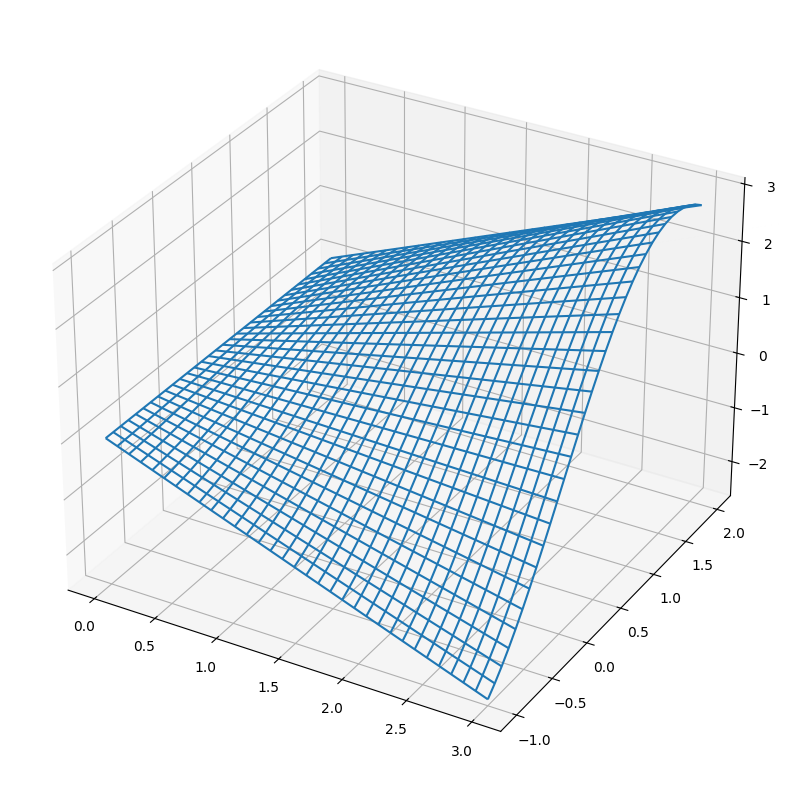

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x=np.linspace(0,3,33)
y=np.linspace(-1,2,33)

X, Y = np.meshgrid(x, y)
Z=X*np.sin(Y)
print(Z)

fig = plt.figure(figsize=(15,10))
ax = plt.axes(projection='3d')
ax.plot_wireframe(X,Y,Z)
#plt.show() # sembla que no cal

Ara podem veure què passa si guardem els valors de la funció en una matriu (tal com faríem si aproximéssim la solució d'una EDP).

Fem el dibuix dels valors guardats a A de la mateixa funció que hem calculat abans.

Les dues funcions haurien de ser la mateixa, però una és la "transposada de l'altra. Això és així perquè, en una matriu, l'element A[i][j] és l'element de a fila i, columna j, i per a nosaltres, és f(x_i,y_j). Per tant, el dibuix correcte és el de Z, i per dibuixar bé la funció utilitzant la matriu A, hauríem de transposar-la.

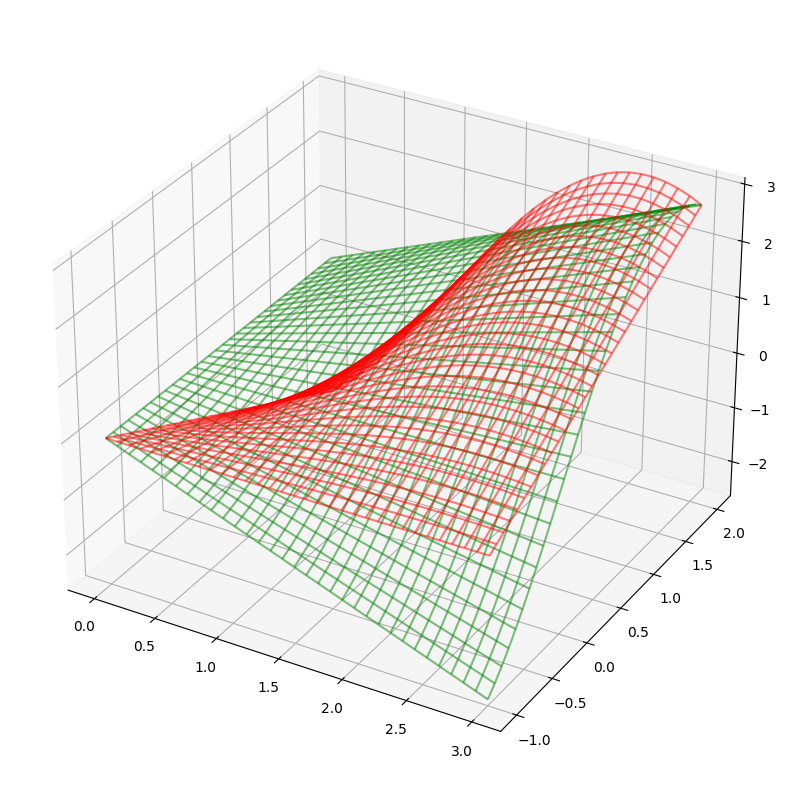

In [ ]:
A=np.zeros((33,33))
for i in range(33):
  for j in range(33):
    A[i][j]=x[i]*np.sin(y[j])

X, Y = np.meshgrid(x, y)
Z=X*np.sin(Y)

fig = plt.figure(figsize=(15,10))
ax = plt.axes(projection='3d')
ax.plot_wireframe(X,Y,Z, color='green',alpha=0.5)
ax.plot_wireframe(X,Y,A, color='red',alpha=0.5)

#plt.show() # sembla que no cal


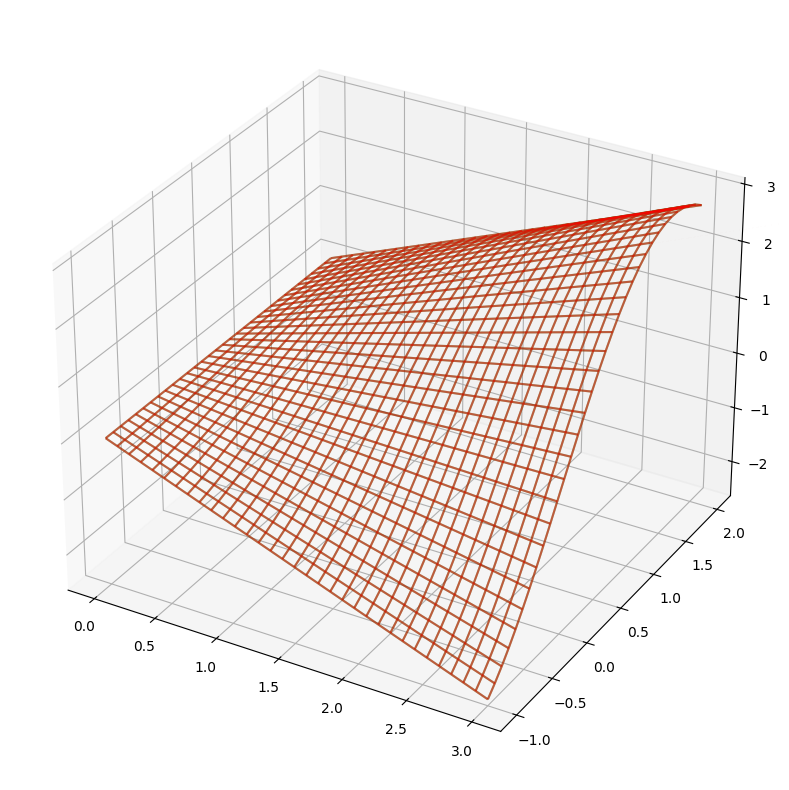

In [ ]:
B=A.transpose()
X, Y = np.meshgrid(x, y)
Z=X*np.sin(Y)

fig = plt.figure(figsize=(15,10))
ax = plt.axes(projection='3d')
ax.plot_wireframe(X,Y,Z, color='green',alpha=0.5)
ax.plot_wireframe(X,Y,B, color='red',alpha=0.5)

plt.show() # sembla que no cal

# <font color='red'> Observació. Què fa la funció `np.meshgrid()`</font>

In [ ]:
import numpy as np

x = np.array([0,1,2,3,4])
y = np.array([5,6,7,8])

X,Y = np.meshgrid(x,y)

print("X = ",X)
print("Y = ",Y)

X =  [[0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]]
Y =  [[5 5 5 5 5]
 [6 6 6 6 6]
 [7 7 7 7 7]
 [8 8 8 8 8]]


Les files de `X` són totes iguals al vector `x`, i les columnes de `Y`són totes iguals al vector `y`.

Quan els elements de X i de Y s'aparellen formant els punts de la malla.

En el cas de l'exemple:

`X = 0 1 2 3 4 0 1 2 3 4...`

`Y = 5 5 5 5 5 6 6 6 6 6...`

i tenim els punts:

`[0,5] [1,5] [2,5] [3,5] [4,5]`

`[0,6] [1,6] [2,6] [3,6] [4,6]`

`...`


# <font color='green'> Operacions amb matrius: transposar i *flipejar*.</font>

In [ ]:
import numpy as np

A=np.zeros((6,8))
for i in range(6):
  for j in range(8):
    A[i][j]= 10*i+j
At = A.transpose()
Af = np.flipud(A)
Atf = np.flipud(At)

print("A")
print(A)
print("TRANSPOSADA")
print(At)
print("FLIPEJADA")
print(Af)
print("PRIMER TRANSPOSADA I DESPRES FLIPEJADA")
print(Atf)

#   PRIMER FLIPEJAR I DESPRÉS TRANSPOSAR NO FUNCIONA


# Faig una matriu Z que sigui la funció "U(x,y)" tal com en els codis de les solucions.
# La funció U és la mateixa que la que la que he usat per definir la matriiu A.
# Potser es pot fer d'una altra manera, però això permet aplicar la funció
# a cadascun dels elements de la matriu, amb una sola línia.
x=np.linspace(0,5,6)
y=np.linspace(0,5,6)

X,Y = np.meshgrid(x,y)
Z=10*X+Y
print("AMB MESHGRID")
print(Z)


X2,Y2 = np.mgrid[0:6:1,0:6:1]
Z2=10*X2+Y2
print("AMB MGRID")
print(Z2)

A
[[ 0.  1.  2.  3.  4.  5.  6.  7.]
 [10. 11. 12. 13. 14. 15. 16. 17.]
 [20. 21. 22. 23. 24. 25. 26. 27.]
 [30. 31. 32. 33. 34. 35. 36. 37.]
 [40. 41. 42. 43. 44. 45. 46. 47.]
 [50. 51. 52. 53. 54. 55. 56. 57.]]
TRANSPOSADA
[[ 0. 10. 20. 30. 40. 50.]
 [ 1. 11. 21. 31. 41. 51.]
 [ 2. 12. 22. 32. 42. 52.]
 [ 3. 13. 23. 33. 43. 53.]
 [ 4. 14. 24. 34. 44. 54.]
 [ 5. 15. 25. 35. 45. 55.]
 [ 6. 16. 26. 36. 46. 56.]
 [ 7. 17. 27. 37. 47. 57.]]
FLIPEJADA
[[50. 51. 52. 53. 54. 55. 56. 57.]
 [40. 41. 42. 43. 44. 45. 46. 47.]
 [30. 31. 32. 33. 34. 35. 36. 37.]
 [20. 21. 22. 23. 24. 25. 26. 27.]
 [10. 11. 12. 13. 14. 15. 16. 17.]
 [ 0.  1.  2.  3.  4.  5.  6.  7.]]
PRIMER TRANSPOSADA I DESPRES FLIPEJADA
[[ 7. 17. 27. 37. 47. 57.]
 [ 6. 16. 26. 36. 46. 56.]
 [ 5. 15. 25. 35. 45. 55.]
 [ 4. 14. 24. 34. 44. 54.]
 [ 3. 13. 23. 33. 43. 53.]
 [ 2. 12. 22. 32. 42. 52.]
 [ 1. 11. 21. 31. 41. 51.]
 [ 0. 10. 20. 30. 40. 50.]]
AMB MESHGRID
[[ 0. 10. 20. 30. 40. 50.]
 [ 1. 11. 21. 31. 41. 51.]
 [ 2. 12. 22. 

# <font color='red'> Les matrius `W` que aproximen les solucions de les equacions en derivades parcials
</font>

La notació que fem servir és
$$
W=\left(
\begin{array}{cccc}
w_{0,3} & w_{1,3}& w_{2,3}& w_{3,3}\\
w_{0,2} & w_{1,2}& w_{2,2}& w_{3,2}\\
w_{0,1} & w_{1,1}& w_{2,1}& w_{3,1}\\
w_{0,0} & w_{1,0}& w_{2,0}& w_{3,0}
\end{array}
  \right)
$$

Per tant, no es correspon amb la notació de matrius i tampoc amb la de `np.meshgrid()`de `numpy`.

# <font color='red'> Observació</font>

* Si volem fer càlculs i no ens cal dibuixar, podem treballar amb la matriu tal com ens la dona `numpy`!
* Si volem veure els resultats en la mateixa notació que a la teoria, la transformació de la matriu `W`que ens ho permet és primer transposar-la i després fer `np.flipud`, com podeu observar en l'exemple anterior.
* Si volem fer la gràfica de la solució, hem de transposar la matriu `W` per tal que els valors de la funció i els eixos OX i OY estiguin sincronitzats.
